# Avance 3 — Modelo de referencia

**Bioactive AI** · Equipo 7 · Maestría en Inteligencia Artificial Aplicada (TC5035.10)

Entrena las tres canalizaciones candidatas de la [1.5](../docs/decisiones.md#d1-5) sobre las matrices que dejaron el [Avance 2](../notebooks/02_Feature_Eng.ipynb) y su [compañero de actividad](../notebooks/02b_Feature_Eng_actividad.ipynb), y mide con validación cruzada agrupada por estructura.

## Qué es un modelo de referencia aquí, y qué no

**Es** el punto contra el que se comparan los modelos de los Avances 4 y 5: tres familias **sin afinar**, la misma partición y las mismas métricas. «Sin afinar» no es «por omisión»: el bosque lleva 300 árboles y `min_samples_leaf=2`, y la logística `max_iter=3000` para que converja. Son valores fijados una vez y no buscados, que es lo que hace comparable el ejercicio; búsqueda de hiperparámetros es del Avance 4. **No es** un modelo afinado, ni una afirmación de desempeño final, ni un ganador — con una sola configuración por familia, decir que una gana es exactamente el error que la [1.5](../docs/decisiones.md#d1-5) ya cometió una vez y tuvo que retirar.

## Lo que este notebook hace distinto, y por qué

Las tres decisiones que todavía pueden cambiar en el proyecto son **qué se predice**, **con qué entradas** y **dónde se corta**. Ninguna vive dentro del código de aquí:

```python
t = cargar("actividad", umbral_um=1.0, representacion="descriptores+diana")
res, fdp = evaluar(canalizaciones(), t.X, t.y, t.grupos, estratos=t.estratos)
```

Cambiar el umbral es cambiar un número y cambiar la representación es cambiar una palabra. Es la lección que la fase 1 aprendió al revés: el Avance 2 seleccionó sus columnas sobre una matriz ya transformada, así que cambiar la transformación obligaba a repetir la selección entera. Se corrigió filtrando sobre los valores crudos, y las 151 columnas de hoy son las mismas con cualquiera de las tres transformaciones.

Y el escalado va **dentro** de la canalización, que se reajusta en cada pliegue. Ajustarlo antes de partir filtra la media y la varianza del pliegue de evaluación.

## 1. Preparación

In [1]:
import sys, warnings, platform
warnings.filterwarnings("ignore")
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# Se inserta la raíz y no `src/`: `src.models.tareas` importa de `src.data_prep`,
# que a su vez importa de `src.features`. Es la convención del 02b y las pruebas.
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from src.evaluation.cv import intervalo_por_grupos, resumen
from src.models import cargar

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (8, 4.2)})
DATOS = RAIZ / "notebooks/datos"

print(f"Python {platform.python_version()} · pandas {pd.__version__}"
      f" · scikit-learn {sklearn.__version__}")

Python 3.12.12 · pandas 3.0.6 · scikit-learn 1.9.1


Los resultados los produce `scripts/experimento_baseline.py`, que registra cada corrida en `experimentos/` con su entorno y sus parámetros. Este notebook **no reentrena**: lee los CSV versionados, que es lo que permite reejecutarlo sin repetir horas de cómputo.

```bash
python scripts/experimento_baseline.py
python scripts/experimento_baseline.py --tarea actividad --representacion descriptores+diana
```

In [2]:
res1 = pd.read_csv(DATOS / "baseline_permeabilidad-descriptores.csv")
res2 = pd.read_csv(DATOS / "baseline_actividad-descriptores-diana-10um.csv")

for nombre, r in (("permeabilidad", res1), ("actividad", res2)):
    g = r[r.estrato.eq("todos")]
    print(f"{nombre:<14} {r.modelo.nunique()} modelos ·"
          f" {g.semilla.nunique()}×{g.pliegue.nunique()} evaluaciones ·"
          f" objetivo: {r.objetivo.iloc[0]}")

permeabilidad  3 modelos · 3×5 evaluaciones · objetivo: bbb_class (BBB+ = 1)
actividad      3 modelos · 3×5 evaluaciones · objetivo: activo a 10 µM


## 2. Fase 1 · Permeabilidad de la barrera

La matriz son los 171 descriptores que sobrevivieron al filtrado del Avance 2, **sin transformar**: la versión transformada que quedó guardada lleva Yeo-Johnson aplicado sobre todas las filas de entrenamiento, así que usarla en validación cruzada mete en cada pliegue de evaluación información ajustada con él.

La prueba reservada no se toca. Todo esto ocurre dentro de entrenamiento y validación.

In [3]:
print(resumen(res1[res1.estrato.eq("todos")]).to_string())

                      mcc         auprc_minoritaria           auroc        
                     mean     std              mean     std    mean     std
estrato modelo                                                             
todos   boosting   0.7019  0.0633            0.8843  0.0337  0.9302  0.0254
        bosque     0.6996  0.0710            0.8950  0.0356  0.9329  0.0267
        logistica  0.6866  0.0663            0.8724  0.0423  0.9133  0.0335


**La desviación de esa tabla no es un error estándar.** Las tres semillas comparten las mismas filas, así que los quince valores no son quince réplicas independientes. Para decidir si dos modelos se distinguen hace falta remuestrear **grupos**, que es la unidad independiente: los compuestos del mismo andamio comparten química y van juntos en la partición.

In [4]:
t1 = cargar("permeabilidad")
print(f"{t1}\n")

# Las predicciones fuera de pliegue se recalculan aquí solo para el intervalo;
# el ajuste ya lo hizo el script y sus cifras están en el CSV.
from src.evaluation.cv import evaluar
from src.models import canalizaciones

_, fdp1 = evaluar(canalizaciones(), t1.X, t1.y, t1.grupos, semillas=(0,), verboso=False)
filas = []
for nombre, p in fdp1.items():
    a, lo, hi = intervalo_por_grupos(t1.y, np.nanmean(p, axis=0), t1.grupos)
    filas.append({"modelo": nombre, "AUROC": a, "IC 95% bajo": lo, "IC 95% alto": hi})
pd.DataFrame(filas).set_index("modelo").round(4)

Tarea(permeabilidad, 6,306×151, objetivo=bbb_class (BBB+ = 1), 65.0% positivos, 1,048 grupos)



,AUROC,IC 95% bajo,IC 95% alto
modelo,,,
logistica,0.9138,0.8889,0.9354
bosque,0.9363,0.9122,0.9545
boosting,0.9356,0.9104,0.9545


**Los intervalos de las tres se solapan**, así que el baseline no elige ganador: establece el nivel contra el que comparar. Y eso vale también para la logística: su intervalo, [0.889, 0.935], se solapa con el del bosque, [0.912, 0.955], en más de lo que separa a sus estimaciones puntuales. **Con este instrumento no se distingue de los árboles**, aunque quede por debajo en los 15 pliegues; decir que sí sería aplicar dos criterios opuestos a la misma evidencia en dos frases seguidas.

Distinguirlas pediría el intervalo de la **diferencia pareada** —bootstrap de grupos sobre la diferencia, o el error estándar corregido de Nadeau y Bengio que usa la [1.5](../docs/decisiones.md#d1-5) para los escaladores—, no los intervalos de cada modelo por separado. No está medido aquí.

### 2.1 Lo que infla agrupar mal

El criterio de agrupamiento no es un detalle de implementación. Agrupar solo por andamio de Bemis-Murcko, en vez de unir andamio y esqueleto de conectividad, separa estereoisómeros del mismo compuesto entre pliegues:

In [5]:
from src.data_prep.splits import SIN_ANDAMIO

andamio_solo = t1.meta["andamio"].fillna(SIN_ANDAMIO).to_numpy()
comparacion = []
for etiqueta, g in (("andamio ∪ esqueleto (el correcto)", t1.grupos),
                    ("solo andamio", andamio_solo)):
    r, f = evaluar({"bosque": canalizaciones()["bosque"]}, t1.X, t1.y, g,
                   semillas=(0,), verboso=False)
    a, lo, hi = intervalo_por_grupos(t1.y, np.nanmean(f["bosque"], axis=0), g)
    comparacion.append({"agrupamiento": etiqueta, "grupos": len(np.unique(g)),
                        "AUROC": round(a, 4), "IC bajo": round(lo, 4),
                        "IC alto": round(hi, 4),
                        "MCC": round(r[r.estrato.eq("todos")]["mcc"].mean(), 4)})
pd.DataFrame(comparacion).set_index("agrupamiento")

,grupos,AUROC,IC bajo,IC alto,MCC
agrupamiento,,,,,
andamio ∪ esqueleto (el correcto),1048,0.9363,0.9122,0.9545,0.6989
solo andamio,2239,0.9586,0.9408,0.9725,0.7694


**Agrupar solo por andamio infla el AUROC en 2.2 puntos y el MCC en 7.1.**

Las dos comparaciones que siguen toman, en cada métrica, **el par de modelos más lejano de esa métrica**, que no es el mismo par: en MCC son el boosting y la logística (0.0153; el bosque contra la logística da 0.0130) y en AUROC el bosque y la logística.

**En MCC el agrupamiento pesa mucho más que la elección de modelo**: mueve 7.1 puntos contra 2.2, algo más de tres veces. Las dos con la misma medida —una semilla, media de pliegues—; compararlas con estimadores distintos daba 4.6. **En AUROC no**: con el mismo estimador de la celda de arriba —una semilla, predicciones fuera de pliegue, bootstrap de grupos— el agrupamiento mueve 0.0223 y la distancia entre el bosque y la logística 0.0225, es decir lo mismo. Compararlos con estimadores distintos, como hacía una versión anterior de esta celda, invertía el resultado sin que se notara.

Lo que sí se sostiene con cualquiera de los dos: **una cifra de este proyecto que no diga cómo agrupó no se puede comparar** con estas.

### 2.2 Qué características pesan, y qué pasa cuando se pregunta dos veces

La explicabilidad es requisito de la patrocinadora, no un adorno ([C.2](../docs/decisiones.md#dc-2)), y la regla del proyecto es **no creerle a un solo método de atribución**. Aquí van dos que miden cosas distintas:

- **Impureza del bosque**: cuánto baja el desorden al cortar por esa columna. Es barata, pero favorece a las variables con muchos valores distintos, así que por sí sola no se reporta.
- **Permutación sobre el pliegue de evaluación**: cuánto AUROC pierde el modelo cuando esa columna se baraja. Mide lo que el modelo **necesita para generalizar**, no lo que memorizó; por eso se calcula fuera del pliegue de ajuste.

Y como tercer control, los coeficientes de la regresión logística, que es el modelo interpretable que la [C.2](../docs/decisiones.md#dc-2) pide entrenar al lado.

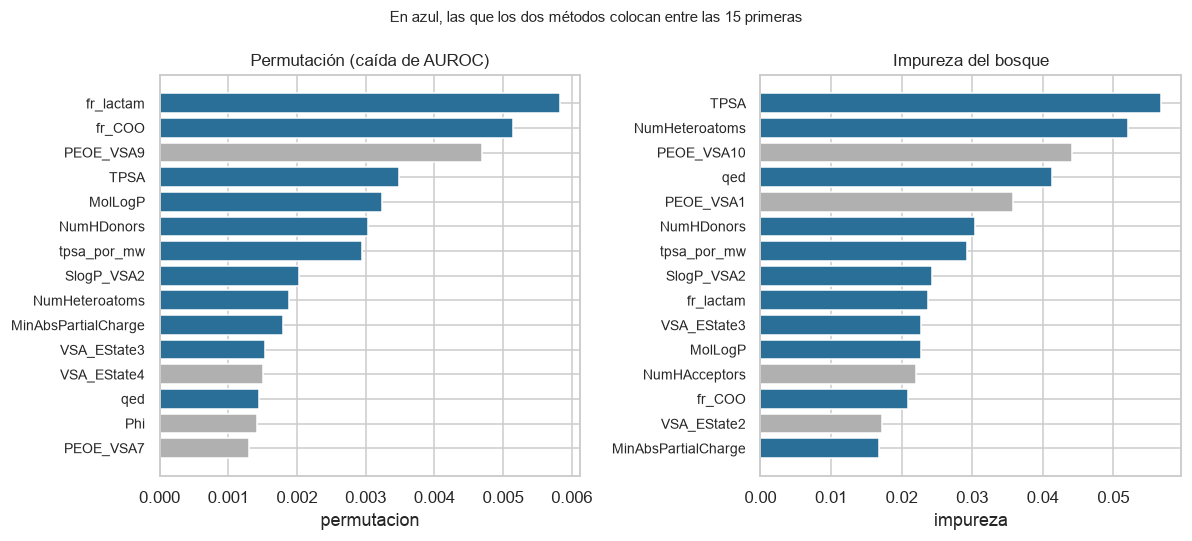

coinciden 11 de 15: MinAbsPartialCharge, MolLogP, NumHDonors, NumHeteroatoms, SlogP_VSA2, TPSA, VSA_EState3, fr_COO, fr_lactam, qed, tpsa_por_mw

características cuya permutación no daña al modelo (≤ 0): 24 de 151

los cinco clásicos de permeabilidad, con los tres métodos:
                impureza  permutacion  coef_logistica
caracteristica                                       
TPSA              0.0568       0.0035         -1.4246
NumHDonors        0.0304       0.0030         -2.4272
NumHAcceptors     0.0221       0.0002          0.2037
MolLogP           0.0228       0.0032          0.7320
MolWt             0.0091      -0.0001         -0.5894


In [6]:
imp = pd.read_csv(DATOS / "rubrica3_importancias.csv")
med = imp.groupby("caracteristica")[["impureza", "permutacion", "coef_logistica"]].mean()

top_perm = med.sort_values("permutacion", ascending=False).head(15)
top_imp = med.sort_values("impureza", ascending=False).head(15)
coinciden = sorted(set(top_perm.index) & set(top_imp.index))

fig, ejes = plt.subplots(1, 2, figsize=(11, 5), sharey=False)
for eje, (tabla, col, titulo) in zip(ejes, [
        (top_perm, "permutacion", "Permutación (caída de AUROC)"),
        (top_imp, "impureza", "Impureza del bosque")]):
    # Las que los dos métodos señalan van en color; las que solo uno, en gris.
    colores = ["#2a6f97" if c in coinciden else "#b0b0b0" for c in tabla.index]
    eje.barh(range(len(tabla)), tabla[col].values, color=colores)
    eje.set_yticks(range(len(tabla)), tabla.index, fontsize=9)
    eje.invert_yaxis()
    eje.set_title(titulo, fontsize=11)
    eje.set_xlabel(col)
fig.suptitle("En azul, las que los dos métodos colocan entre las 15 primeras", fontsize=10)
plt.tight_layout()
plt.show()

print(f"coinciden {len(coinciden)} de 15: {', '.join(coinciden)}")
print(f"\ncaracterísticas cuya permutación no daña al modelo (≤ 0): "
      f"{int((med['permutacion'] <= 0).sum())} de {len(med)}")
print("\nlos cinco clásicos de permeabilidad, con los tres métodos:")
print(med.loc[[c for c in ["TPSA", "NumHDonors", "NumHAcceptors", "MolLogP", "MolWt"]
               if c in med.index]].round(4).to_string())

**Los dos métodos coinciden en 11 de las 15 primeras, y discrepan en el orden.** La impureza pone a **TPSA** arriba; la permutación pone a `fr_lactam` y `fr_COO`, dos conteos de grupos funcionales. No es contradicción: la impureza premia a una variable continua con muchos cortes posibles, y la permutación mide el daño real de perderla. Lo que se reporta es la intersección, que es la regla del proyecto.

**Y la intersección dice lo que la literatura dice.** TPSA, donadores de hidrógeno y `MolLogP` están en las dos listas, y los coeficientes de la logística les dan el signo esperado: TPSA −1.42 y donadores −2.43, es decir que **más polaridad y más donadores empujan hacia BBB−**. Es la regla de los dos parámetros que `CLAUDE.md` exige como verificación de cualquier afirmación estructural, obtenida aquí por tres caminos independientes en vez de citada.

**24 de las 151 columnas no dañan al modelo al permutarlas, y esa cuenta hay que leerla con su ruido.** El CSV guarda la desviación de las cinco repeticiones de cada permutación, y en solo 4 de esas 24 la media supera en magnitud a su propia desviación: para las otras 20 el signo es compatible con el azar. En toda la matriz, solo 75 de 151 columnas tienen una media mayor que su desviación, así que **el orden de la cola de esta tabla no está medido**; el de la cabeza sí —`fr_lactam` da 0.0058 ± 0.0012, casi cinco veces su desviación—, y es de donde sale la intersección de arriba.

No se retira ninguna: quitarlas es una decisión del Avance 4, con los modelos afinados y con repeticiones suficientes para que el signo signifique algo. Queda registrado como candidato de poda, no como lista.

### 2.3 ¿Sobreajusta? La brecha, y si se cierra con más datos

Una cifra de validación no dice si el modelo memorizó. Hace falta la misma métrica sobre el pliegue de ajuste, y la **curva de aprendizaje** para distinguir dos diagnósticos que se confunden: si la brecha se cierra al crecer el entrenamiento, falta data; si no se cierra, sobra capacidad.

           mcc_ajuste  mcc_validacion  auroc_ajuste  auroc_validacion  brecha_mcc  brecha_auroc
modelo                                                                                         
logistica      0.7385          0.6866        0.9426            0.9133      0.0519        0.0293
bosque         0.9546          0.6984        0.9980            0.9331      0.2562        0.0649
boosting       0.9715          0.7019        0.9992            0.9302      0.2696        0.0690


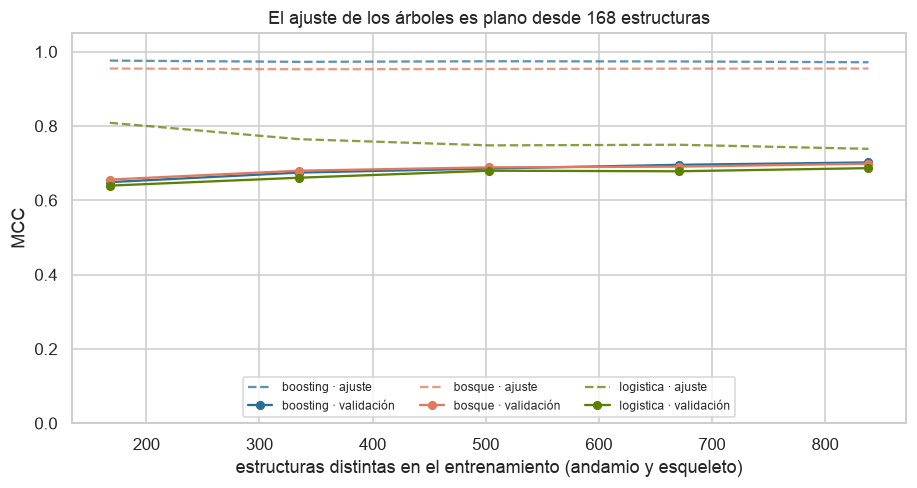


lo que gana el último 20% de estructuras, en MCC de validación:
  boosting   +0.0063
  bosque     +0.0078
  logistica  +0.0085


In [7]:
aju = pd.read_csv(DATOS / "rubrica3_ajuste.csv")
tabla = (aju.groupby("modelo")[["mcc_ajuste", "mcc_validacion",
                                "auroc_ajuste", "auroc_validacion",
                                "brecha_mcc", "brecha_auroc"]]
         .mean().round(4).sort_values("brecha_mcc"))
print(tabla.to_string())

cur = pd.read_csv(DATOS / "rubrica3_curva.csv")
# Se promedia por **fracción** y no por el conteo exacto de grupos: cada pliegue
# y cada semilla dejan un número distinto, así que agrupar por el conteo pone un
# punto por corrida y la línea sale dentada sin que eso signifique nada.
eje_x = cur.groupby("fraccion")["grupos"].mean()

fig, eje = plt.subplots(figsize=(8.5, 4.6))
for color, modelo in zip(["#2a6f97", "#e07a5f", "#5c8001"], sorted(cur.modelo.unique())):
    g = cur[cur.modelo.eq(modelo)].groupby("fraccion")[["mcc_ajuste", "mcc_validacion"]].mean()
    eje.plot(eje_x[g.index], g["mcc_ajuste"], "--", color=color, alpha=0.75,
             label=f"{modelo} · ajuste")
    eje.plot(eje_x[g.index], g["mcc_validacion"], "-o", color=color, ms=5,
             label=f"{modelo} · validación")
eje.set(xlabel="estructuras distintas en el entrenamiento (andamio y esqueleto)",
        ylabel="MCC", ylim=(0, 1.05),
        title="El ajuste de los árboles es plano desde 168 estructuras")
eje.legend(fontsize=8, ncol=3, loc="lower center")
plt.tight_layout()
plt.show()

ult = cur[cur.fraccion.isin([0.8, 1.0])].groupby(["modelo", "fraccion"])["mcc_validacion"].mean()
print("\nlo que gana el último 20% de estructuras, en MCC de validación:")
for m in sorted(cur.modelo.unique()):
    print(f"  {m:<10} {ult[(m, 1.0)] - ult[(m, 0.8)]:+.4f}")

**Los dos modelos de árboles sobreajustan y la logística casi no.** El bosque y el boosting llegan a 0.95 y 0.97 de MCC sobre el pliegue de ajuste contra 0.70 en validación: una brecha de 0.26 y 0.27. La logística va de 0.74 a 0.69, brecha de 0.05. En AUROC la diferencia es la misma historia más comprimida, 0.999 contra 0.930.

**Y la curva separa los dos diagnósticos, aunque no como «se cierra o no se cierra».** En los árboles la línea de ajuste es **plana** desde 168 estructuras, pegada a 0.95 y 0.97: memorizan el entrenamiento completo sea cual sea su tamaño. En la logística la línea de ajuste **baja** —de 0.81 a 0.74— y se acerca a la de validación, que es el cuadro de un modelo con la capacidad acotada por su forma lineal.

**La brecha de los árboles sí se cierra, y conviene decirlo porque la figura invita a lo contrario**: entre la quinta parte de las estructuras y todas, va de 0.327 a 0.270 en boosting y de 0.299 a 0.256 en el bosque. Son 5.8 y 4.3 puntos, más que la brecha **entera** de la logística, que es de 5.2. Lo que no se cierra es la distancia que falta: quintuplicar las estructuras quitó una quinta parte de la brecha, así que cerrarla por este camino pediría órdenes de magnitud más compuestos.

Y se cierra por el lado equivocado: no porque el ajuste baje —es plano— sino porque la validación sube, de 0.649 a 0.702 en boosting, cada vez menos: el último 20% de estructuras aporta menos de una centésima en los tres modelos. Así que **más compuestos del mismo tipo ayudarían poco**; lo que falta es regularizar los árboles, que es trabajo del Avance 4.

**Esto no invalida el baseline, lo sitúa.** Un modelo con esta brecha sigue siendo un punto de referencia válido —se mide fuera del pliegue y la prueba no se toca— pero fija dónde buscar mejora: `min_samples_leaf`, profundidad y número de árboles, no más descriptores.

### 2.4 El piso: contra qué se lee un 0.70

No existe un desempeño histórico con el que comparar: la patrocinadora no tenía modelo previo, y las cifras publicadas sobre BBBP van de 0.681 a 0.7194 de AUROC según quién las reporte, sobre otro conjunto y otra partición, así que no sirven de meta ([1.5](../docs/decisiones.md#d1-5)). El piso se mide entonces aquí, con clasificadores que no miran la molécula y **la misma partición agrupada**:

In [8]:
piso = pd.read_csv(DATOS / "rubrica3_piso.csv")
print(piso.groupby("modelo")[["mcc", "auprc_minoritaria", "auroc"]].mean().round(4).to_string())
print(f"\nproporción de BBB+ en el conjunto: {t1.y.mean():.1%}"
      f" · la clase minoritaria (BBB−) es el {1 - t1.y.mean():.1%}")

                         mcc  auprc_minoritaria   auroc
modelo                                                 
al azar (proporción) -0.0125             0.3478  0.4938
mayoritaria           0.0000             0.3503  0.5000
proporción constante  0.0000             0.3503  0.5000

proporción de BBB+ en el conjunto: 65.0% · la clase minoritaria (BBB−) es el 35.0%


**El piso es 0.000 de MCC y 0.500 de AUROC**, y conviene decir por qué no es obvio: con 65.0% de BBB+, un clasificador que diga siempre «permeable» acierta dos de cada tres veces. Esa exactitud del 65% parecería un resultado, y por eso **la métrica de este proyecto no es la exactitud**: MCC y AUROC le dan 0.000 y 0.500, que es lo que vale no mirar la molécula.

**El AUPRC no tiene piso cero**, y por eso va en la tabla: el trivial alcanza 0.350, que es la proporción de la clase minoritaria. El 0.88 del baseline se lee contra ese 0.350 y no contra 0, así que la mejora es menor de lo que la cifra sugiere a primera vista. Es la misma trampa que la exactitud, en la métrica que la evita.

**El desempeño mínimo aceptable para el Avance 4 queda fijado aquí**: cualquier modelo que no supere de forma clara el 0.70 de MCC y el 0.93 de AUROC de este baseline, medido con esta partición y estas semillas, no justifica su complejidad añadida. Es un piso del proyecto, no de la literatura, y eso es deliberado: es el único que se midió sobre estos datos con este criterio de agrupamiento.

## 3. Fase 2 · Actividad en el sistema nervioso

La unidad es el **par compuesto-diana** y el objetivo se guarda como intervalo, así que el corte de «activo» es una decisión de lectura ([2.10](../docs/decisiones.md#d2-10)). Aquí va el vigente, 10 µM, con la diana como característica: sin ella el modelo no sabe contra qué se mide. Sobre las 25 dianas de esta matriz con 50 pares o más, la tasa de activos va de **34.8% en `MAOA` a 98.4% en `IL6`**; el 96.9% que esta celda citaba antes es el de `GRIN2B` y sale de la [2.2](../docs/decisiones.md#d2-2), que describe otro subconjunto.

In [9]:
print(resumen(res2[res2.estrato.eq("todos")]).to_string())

                      mcc         auprc_minoritaria           auroc        
                     mean     std              mean     std    mean     std
estrato modelo                                                             
todos   boosting   0.4863  0.0180            0.7115  0.0119  0.8512  0.0102
        bosque     0.4948  0.0170            0.7240  0.0109  0.8629  0.0086
        logistica  0.3871  0.0189            0.6114  0.0091  0.7952  0.0114


### 3.1 El agregado no describe a los productos naturales

Es el resultado del [control de atajo](../docs/decisiones.md#d2-3), y obliga a que ninguna métrica de esta fase se publique sin su desglose:

In [10]:
por_estrato = (res2[res2.modelo.eq("bosque")]
               .groupby("estrato")[["n", "activos", "mcc", "auroc"]]
               .mean().round(4).sort_values("n", ascending=False))
por_estrato

,n,activos,mcc,auroc
estrato,,,,
todos,10873.8,0.7139,0.4948,0.8629
solo_chembl,10134.2,0.7484,0.4624,0.8546
solo_npass,421.8,0.1239,0.0986,0.6072
mixto,317.6,0.4019,0.2036,0.6410


La diferencia entre `solo_chembl` y `solo_npass` no es ruido de un pliegue: es el modelo separando mucho peor justo los compuestos que el proyecto existe para priorizar. Lo que todavía **no** se puede afirmar es que no sirva para ellos — a igual diana solo hay tres con datos suficientes, y el cuadro es heterogéneo ([2.3](../docs/decisiones.md#d2-3)).

## 4. Qué queda establecido, y qué no

1. **Hay nivel de referencia para las dos fases**, con la misma partición, las mismas métricas y el mismo arnés, registrado en `experimentos/`.
2. **Ningún modelo gana.** Los intervalos de las tres canalizaciones se solapan en la fase 1; con una configuración por familia, afirmar un ganador sería repetir un error que este proyecto ya retiró una vez.
3. **El agrupamiento vale más que el modelo en MCC, y lo mismo en AUROC.** Agrupar bien o mal mueve 7.1 puntos de MCC contra 2.2 entre las tres familias; en AUROC mueve 2.2 contra 2.2, es decir lo mismo. La conclusión fuerte es la de MCC, y solo vale comparando las dos cifras con el **mismo** estimador: hacerlo con estimadores distintos daba «2.2 contra menos de 2» e invertía el resultado.
4. **El desempeño de la fase 2 no es un número**, es uno por estrato de procedencia, y la cifra que contesta la pregunta del proyecto es la de los naturales.
5. **La selección de características se ajustó antes de partir, y es una limitación declarada.** Las 151 columnas salieron del notebook 02 mirando todo el entrenamiento, y la validación cruzada de aquí reparte esas mismas filas entre pliegues: cada pliegue de evaluación contiene filas cuyas etiquetas ayudaron a elegir las columnas. El filtro de casi constancia y el de correlación de Spearman son casi insensibles a la etiqueta, pero el desempate entre dos columnas correlacionadas usa la F de ANOVA contra la etiqueta, así que la fuga existe aunque sea pequeña. **Es la misma clase de fuga que este notebook evita al no usar la matriz transformada**, y por eso se declara en vez de callarse: medirla pide meter la selección dentro de la canalización y reejecutar, que es trabajo del Avance 4.
6. **La prueba reservada sigue sin mirarse.** Su guarda es el [#54](https://github.com/AntonioVazquezMartinez/Bioactive-AI/issues/54) y espera al Avance 5; cuando se mire, hay que declarar antes que trae 117 pares de NPASS puros, así que el intervalo sobre naturales será ancho.

Lo que **no** se decide aquí, a propósito:

| Decisión | Dónde vive |
|:--|:--|
| Hiperparámetros de cada familia | Avance 4 |
| Si se corta en 10 µM o en 1 µM | [2.3](../docs/decisiones.md#d2-3); el intervalo lo hace una columna |
| Si se clasifica o se predice potencia | [2.9](../docs/decisiones.md#d2-9), del Avance 4 |
| Qué representación conviene | [1.3](../docs/decisiones.md#d1-3) y [1.7](../docs/decisiones.md#d1-7); el arnés ya las acepta como argumento |
| El punto de operación del entregable | [C.5](../docs/decisiones.md#dc-5): no se fija, se entrega la curva |